# Retail Analytics

In [46]:
# Cell 2: Import libraries

import os
import re
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from IPython.display import display, HTML
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


# Configure project paths

In [2]:
# Cell 3: Project configuration

DATA_PATH = Path(
    r"C:\Users\amans\Downloads\RETAIL_ANALYTICS.csv"
)

PROJECT_NAME = "Retail Analytics"
RANDOM_STATE = 42

OUTPUT_DIR = Path.cwd() / "retail_analytics_output"
CHART_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_NAME)
print("Dataset:", DATA_PATH)
print("Output directory:", OUTPUT_DIR.resolve())

Project: Retail Analytics
Dataset: C:\Users\amans\Downloads\RETAIL_ANALYTICS.csv
Output directory: C:\Users\amans\retail_analytics_output


# Load CSV Datasets

In [3]:
# Cell 4: Load CSV dataset

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the file path and filename."
    )

try:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
except UnicodeDecodeError:
    df_raw = pd.read_csv(DATA_PATH, encoding="latin1")

df = df_raw.copy()

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 229
Number of columns: 40


,Month,Enquiry Date,Enquiry Id,Allocation Status,Status,State,City,Pincode,Type of Project,No of Windows,Source,Zone,Dealer Name,First Action-Call made,Date DD/MM/YY,First Action-Call Status,Date of Appointment (DD/MM/YY),Second Action-Customer Meeting,Date DD/MM/YY.1,Second Action-Call Status,Third Action-Quote Given,Date DD/MM/YY.2,Q Val. (Rs. Lac),Quote QTY,Order Recd\Lost,Date DD/MM/YY.3,Order Val. (Rs. Lac),Order QTY,Quote ID (as per match to CCC Records),Remarks-Brand and value if lost to UPVC,Second Action-Call Status.1,Remarks,Price Per Sft,Benefits,Aesthetics,Reduce Street Noise,Low Maintenance,Monsoon Proof,Better Lighting,Reduce AC Energy Cost
0,April'16,2-Apr-16,EC02041646800,Dealer,Won,TAMILNADU,CHENNAI,600008,Renovation,6 to 10,Friends or Family,Chennai,Sunbird,Yes,2-Apr-16,Appointment Fixed,4-Apr-16,yes,5-Apr-16,Quote to Be Submitted,yes,6-Apr-16,0.72,3,Order Received,19-Aug-16,0.54,3.0,SPN58634,won,NaN,NaN,1105,Aesthetics & Street Noise,1.0,1.0,0.0,0.0,0.0,0.0
1,April'16,8-Apr-16,EC08041647157,Dealer,Lost,TAMILNADU,CHENNAI,600042,New Construction,6 to 10,Just dial,Chennai,Winfratech,Yes,8-Apr-16,Appointment Fixed,9-Apr-16,yes,10-Apr-16,Further Meeting Required,NaN,NaN,NaN,NaN,Lost to Aluminum,NaN,NaN,NaN,NaN,Budget constraint,NaN,Price Issue,985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,April'16,8-Apr-16,EC08041647130,Dealer,Lost,TAMILNADU,CHENNAI,600015,New Construction,1 to 5,Current User,Chennai,Sunbird,Yes,9-Mar-16,Appointment Fixed,10-Mar-16,yes,11-Apr-16,Quote to Be Submitted,yes,12-Apr-16,8.40,42,Delivery Time Not Possible,NaN,NaN,NaN,NaN,follow up,NaN,Delivery Issue,918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,April'16,9-Apr-16,EC09041647202,Direct,Lost,TAMILNADU,KANCHIPURAM,600075,New Construction,21 to 40,Friends or Family,Chennai,Direct,Yes,9-Apr-16,Appointment Fixed,10-Apr-16,yes,11-Apr-16,Quote to Be Submitted,yes,12-Apr-16,2.00,9,Lost to Aluminum,NaN,NaN,NaN,no response,NaN,NaN,Price Issue,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,April'16,11-Apr-16,EC11041647360,Direct,Won,TAMILNADU,CHENNAI,600041,Renovation,6 to 10,Internet,Chennai,Sunbird,Yes,11-Apr-16,Appointment Fixed,11-Apr-16,yes,13-Apr-16,Quote to Be Submitted,yes,15-Apr-16,1.63,8,Order Received,21-May-16,1.63,8.0,SPN43642,follow up,NaN,NaN,1350,Reduce AC Energy Cost,0.0,0.0,0.0,0.0,0.0,1.0


In [4]:
# Cell 5: Dataset overview

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset dimensions: (229, 40)

Column names:
['Month', 'Enquiry Date', 'Enquiry Id', 'Allocation Status', 'Status', 'State', 'City', 'Pincode', 'Type of Project', 'No of Windows', 'Source', 'Zone', 'Dealer Name', 'First Action-Call made', 'Date DD/MM/YY', 'First Action-Call Status', 'Date of Appointment (DD/MM/YY)', 'Second Action-Customer Meeting', 'Date DD/MM/YY.1', 'Second Action-Call Status', 'Third Action-Quote Given', 'Date DD/MM/YY.2', 'Q Val. (Rs. Lac)', 'Quote QTY', ' Order Recd\\Lost ', 'Date DD/MM/YY.3', 'Order Val. (Rs. Lac)', 'Order QTY', 'Quote ID (as per match to CCC Records)', ' Remarks-Brand and value if lost to UPVC ', 'Second Action-Call Status.1', 'Remarks', 'Price Per Sft', 'Benefits', 'Aesthetics', 'Reduce Street Noise', 'Low Maintenance', 'Monsoon Proof', 'Better Lighting', 'Reduce AC Energy Cost']


In [5]:
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))


Data types:


,Data Type
Month,object
Enquiry Date,object
Enquiry Id,object
Allocation Status,object
Status,object
State,object
City,object
Pincode,int64
Type of Project,object
No of Windows,object


In [6]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229 entries, 0 to 228
Data columns (total 40 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Month                                      229 non-null    object 
 1   Enquiry Date                               229 non-null    object 
 2   Enquiry Id                                 229 non-null    object 
 3   Allocation Status                          229 non-null    object 
 4   Status                                     229 non-null    object 
 5   State                                      229 non-null    object 
 6   City                                       229 non-null    object 
 7   Pincode                                    229 non-null    int64  
 8   Type of Project                            229 non-null    object 
 9   No of Windows                              229 non-null    object 
 10  Sour

In [7]:
print("\nStatistical summary:")
display(df.describe(include="all").T)


Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Month,229,9,July'16,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Enquiry Date,229,150,25-Jul-16,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Enquiry Id,229,228,EC21041648139,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Allocation Status,229,2,Dealer,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,229,2,Lost,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,229,1,TAMILNADU,229,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,229,9,CHENNAI,146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pincode,229.0,NaN,NaN,NaN,601742.572052,6573.378113,600001.0,600033.0,600059.0,600099.0,635810.0
Type of Project,229,2,Renovation,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No of Windows,229,6,1 to 5,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Dictionary

In [8]:
# Cell 6: Create a data dictionary

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing Percentage": (
        df.isna().mean().values * 100
    ).round(2),
    "Unique Values": df.nunique(dropna=True).values
})

display(data_dictionary)

data_dictionary.to_csv(
    TABLE_DIR / "initial_data_dictionary.csv",
    index=False
)

,Column,Data Type,Missing Values,Missing Percentage,Unique Values
0,Month,object,0,0.00,9
1,Enquiry Date,object,0,0.00,150
2,Enquiry Id,object,0,0.00,228
3,Allocation Status,object,0,0.00,2
4,Status,object,0,0.00,2
5,State,object,0,0.00,1
6,City,object,0,0.00,9
7,Pincode,int64,0,0.00,103
8,Type of Project,object,0,0.00,2
9,No of Windows,object,0,0.00,6


In [9]:
# Cell 7: Standardize column names

def clean_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    column = column.strip("_")
    return column or "unnamed_column"

original_columns = df.columns.tolist()
df.columns = [clean_column_name(c) for c in df.columns]

# Handle column names that become duplicated after cleaning
if df.columns.duplicated().any():
    seen = {}
    new_columns = []

    for col in df.columns:
        seen[col] = seen.get(col, 0) + 1
        new_columns.append(
            col if seen[col] == 1 else f"{col}_{seen[col]}"
        )

    df.columns = new_columns

column_mapping = pd.DataFrame({
    "Original Column": original_columns,
    "Cleaned Column": df.columns
})

display(column_mapping)

,Original Column,Cleaned Column
0,Month,month
1,Enquiry Date,enquiry_date
2,Enquiry Id,enquiry_id
3,Allocation Status,allocation_status
4,Status,status
5,State,state
6,City,city
7,Pincode,pincode
8,Type of Project,type_of_project
9,No of Windows,no_of_windows


In [10]:
# Cell 9: Normalize text fields

text_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in text_columns:
    df[col] = df[col].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

# Convert blank strings to missing values
df.replace(r"^\s*$", np.nan, regex=True, inplace=True)

print("Text normalization completed.")

Text normalization completed.


# Detect and convert date columns

In [11]:
# Cell 10: Detect and convert date columns

date_keywords = [
    "date", "order_date", "sales_date",
    "transaction_date", "invoice_date", "timestamp"
]

date_columns = [
    col for col in df.columns
    if any(keyword in col for keyword in date_keywords)
]

date_conversion_results = []

for col in date_columns:
    non_missing_before = df[col].notna().sum()

    converted = pd.to_datetime(
        df[col],
        errors="coerce",
        format="mixed"
    )

    df[col] = converted

    date_conversion_results.append({
        "Column": col,
        "Original Non-Missing": int(non_missing_before),
        "Successfully Parsed": int(converted.notna().sum()),
        "Invalid or Missing": int(converted.isna().sum())
    })

if date_conversion_results:
    display(pd.DataFrame(date_conversion_results))
else:
    print("No obvious date columns detected.")

,Column,Original Non-Missing,Successfully Parsed,Invalid or Missing
0,enquiry_date,229,229,0
1,date_dd_mm_yy,229,229,0
2,date_of_appointment_dd_mm_yy,192,192,37
3,date_dd_mm_yy_1,192,192,37
4,date_dd_mm_yy_2,188,187,42
5,date_dd_mm_yy_3,48,48,181


In [12]:
# Cell 11: Convert likely numeric columns

numeric_keywords = [
    "sales", "revenue", "price", "amount", "quantity",
    "qty", "profit", "discount", "cost", "total",
    "unit_price", "units", "shipping", "tax"
]

numeric_conversion_log = []

for col in df.select_dtypes(
    include=["object", "string"]
).columns.tolist():

    name_suggests_numeric = any(
        keyword in col for keyword in numeric_keywords
    )

    if name_suggests_numeric:
        original = df[col].copy()

        cleaned = (
            original.astype("string")
            .str.replace(r"[$₹€£,\s]", "", regex=True)
            .str.replace(r"^\((.*)\)$", r"-\1", regex=True)
        )

        converted = pd.to_numeric(cleaned, errors="coerce")

        original_nonmissing = original.notna().sum()
        conversion_success = converted.notna().sum()

        # Convert only when the majority of populated values are numeric.
        if original_nonmissing == 0 or (
            conversion_success / original_nonmissing >= 0.70
        ):
            df[col] = converted

            numeric_conversion_log.append({
                "Column": col,
                "Converted": True,
                "Valid Numeric Values": int(conversion_success)
            })

display(pd.DataFrame(numeric_conversion_log))

,Column,Converted,Valid Numeric Values
0,quote_qty,True,182


# Missing Value

,Missing Count,Missing Percentage,Data Type
second_action_call_status_1,229,100.00,float64
reduce_ac_energy_cost,192,83.84,float64
better_lighting,192,83.84,float64
monsoon_proof,192,83.84,float64
low_maintenance,192,83.84,float64
reduce_street_noise,192,83.84,float64
aesthetics,192,83.84,float64
order_val_rs_lac,181,79.04,float64
date_dd_mm_yy_3,181,79.04,datetime64[ns]
order_qty,181,79.04,float64


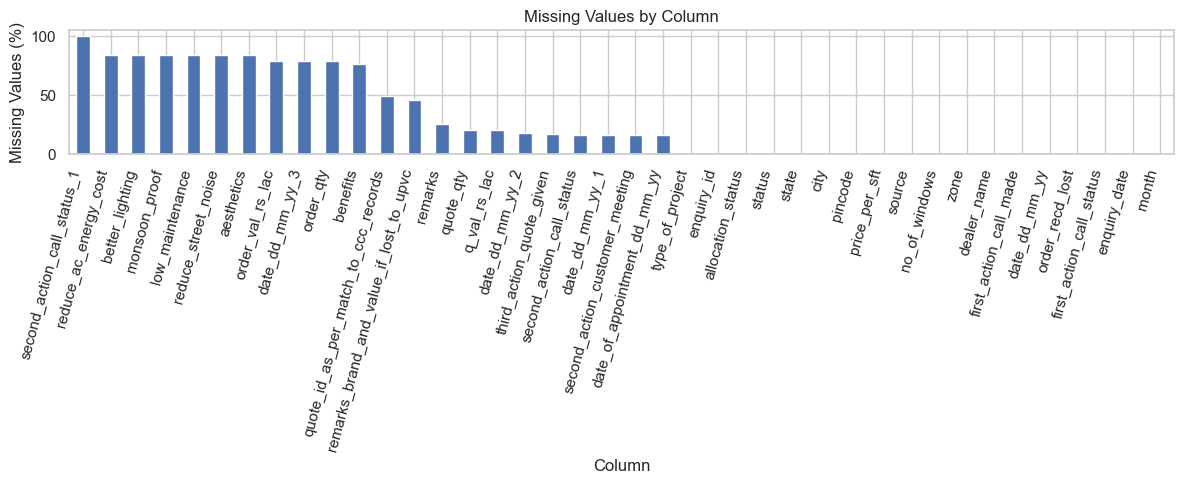

In [13]:
# Cell 12: Inspect missing values

missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})

missing_report = missing_report.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_report)

missing_report.to_csv(
    TABLE_DIR / "missing_values_report.csv"
)

plt.figure(figsize=(12, 5))
missing_report["Missing Percentage"].plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.savefig(CHART_DIR / "missing_values.png", dpi=150)
plt.show()

# Handle Missing Value

In [14]:
# Cell 13: Handle missing values

# Remove columns that contain no useful information
empty_columns = [
    col for col in df.columns
    if df[col].isna().all()
]

if empty_columns:
    print("Dropping completely empty columns:", empty_columns)
    df.drop(columns=empty_columns, inplace=True)

# Remove constant columns only when they contain no analytical variation
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=True) <= 1
]

print("Constant columns:", constant_columns)

# Fill numeric missing values with the median.
# This preserves the original dataset's row count.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols:
    if df[col].isna().any():
        median_value = df[col].median()

        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

# Fill categorical missing values with the mode, if available.
categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

for col in categorical_cols:
    if df[col].isna().any():
        modes = df[col].mode(dropna=True)

        if not modes.empty:
            df[col] = df[col].fillna(modes.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

print("Missing-value treatment completed.")
print("Remaining missing values:", int(df.isna().sum().sum()))

Dropping completely empty columns: ['second_action_call_status_1']
Constant columns: ['state', 'first_action_call_made']
Missing-value treatment completed.
Remaining missing values: 297


# Numeric columns

In [19]:
def numeric_sum(column):
    if column and column in df.columns:
        values = pd.to_numeric(df[column], errors="coerce")
        return float(values.sum()) if values.notna().any() else None
    return None

def unique_count(column):
    if column and column in df.columns:
        return int(df[column].nunique(dropna=True))
    return None

total_sales = numeric_sum(sales_col)
total_profit = numeric_sum(profit_col)
total_quantity = numeric_sum(quantity_col)

kpis = {
    "Total Records": len(df),
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Quantity": total_quantity,
    "Unique Products": unique_count(product_col),
    "Unique Customers": unique_count(customer_col),
    "Unique Orders": unique_count(order_col)
}

kpis["Profit Margin (%)"] = (
    total_profit / total_sales * 100
    if total_sales not in (None, 0) and total_profit is not None
    else None
)

kpi_table = pd.DataFrame([
    {"KPI": key, "Value": value}
    for key, value in kpis.items()
])

display(kpi_table)

kpi_table.to_csv(TABLE_DIR / "retail_kpis.csv", index=False)

,KPI,Value
0,Total Records,229.0
1,Total Sales,NaN
2,Total Profit,NaN
3,Total Quantity,1869.9
4,Unique Products,NaN
5,Unique Customers,2.0
6,Unique Orders,NaN
7,Profit Margin (%),NaN


In [16]:
def find_column(dataframe, candidates):
    # Exact matches first.
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    # Partial matches second.
    for candidate in candidates:
        for col in dataframe.columns:
            if candidate in col:
                return col

    return None


column_roles = {
    "date": ["order_date", "transaction_date", "sales_date",
             "invoice_date", "date", "timestamp"],
    "sales": ["total_sales", "sales_amount", "sales", "revenue",
              "total_amount", "order_value", "amount"],
    "quantity": ["quantity", "qty", "units_sold", "units"],
    "profit": ["net_profit", "gross_profit", "profit_amount", "profit"],
    "price": ["unit_price", "selling_price", "product_price", "price"],
    "cost": ["unit_cost", "cost_price", "total_cost", "cost"],
    "discount": ["discount_amount", "discount_percent", "discount"],
    "product": ["product_name", "product_id", "product", "item_name", "sku"],
    "category": ["product_category", "category", "subcategory"],
    "customer": ["customer_id", "customer_name", "customer", "client_id"],
    "region": ["region", "state", "city", "location", "territory", "country"],
    "order_id": ["order_id", "transaction_id", "invoice_id", "bill_id"],
    "segment": ["customer_segment", "segment", "customer_type"]
}

detected = {
    role: find_column(df, candidates)
    for role, candidates in column_roles.items()
}

display(pd.DataFrame({
    "Business Role": list(detected.keys()),
    "Detected Column": list(detected.values())
}))

sales_col = detected["sales"]
date_col = detected["date"]
profit_col = detected["profit"]
quantity_col = detected["quantity"]
product_col = detected["product"]
category_col = detected["category"]
customer_col = detected["customer"]
region_col = detected["region"]
order_col = detected["order_id"]

,Business Role,Detected Column
0,date,enquiry_date
1,sales,None
2,quantity,quote_qty
3,profit,None
4,price,price_per_sft
5,cost,reduce_ac_energy_cost
6,discount,None
7,product,None
8,category,None
9,customer,second_action_customer_meeting


# KPI Dashboard

In [20]:
def fmt(value):
    if value is None or pd.isna(value):
        return "N/A"
    if isinstance(value, (int, float, np.integer, np.floating)):
        return f"{value:,.2f}"
    return str(value)

cards = ""

for _, row in kpi_table.iterrows():
    cards += f"""
    <div style="flex:1;min-width:155px;margin:6px;padding:18px;
                border:1px solid #ddd;border-radius:10px;">
        <div style="color:#555;font-size:13px;">
            {row['KPI']}
        </div>
        <div style="font-size:23px;font-weight:bold;">
            {fmt(row['Value'])}
        </div>
    </div>
    """

display(HTML(
    f'<div style="display:flex;flex-wrap:wrap;">{cards}</div>'
))

# Numerical Summary

In [21]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    numerical_summary = df[numeric_cols].describe().T
    numerical_summary["median"] = df[numeric_cols].median()
    numerical_summary["missing"] = df[numeric_cols].isna().sum()

    display(numerical_summary)

    numerical_summary.to_csv(
        TABLE_DIR / "numerical_summary.csv"
    )
else:
    numerical_summary = pd.DataFrame()
    print("No numerical columns found.")

,count,mean,std,min,25%,50%,75%,max,median,missing
pincode,229.0,601742.572052,6573.378113,600001.0,600033.0,600059.0,600099.0,635810.0,600059.0,0
q_val_rs_lac,229.0,1.687293,2.33967,0.01,0.66,1.07,1.7,25.0,1.07,0
quote_qty,229.0,8.165502,18.867193,0.6,2.0,4.0,7.0,250.0,4.0,0
order_val_rs_lac,229.0,1.301834,1.091106,0.07,1.15,1.15,1.15,10.95,1.15,0
order_qty,229.0,6.886463,6.992806,1.0,6.0,6.0,6.0,73.0,6.0,0
price_per_sft,229.0,1045.323144,220.032076,650.0,921.0,1030.0,1129.0,3121.0,1030.0,0
aesthetics,229.0,0.039301,0.194737,0.0,0.0,0.0,0.0,1.0,0.0,0
reduce_street_noise,229.0,0.943231,0.231907,0.0,1.0,1.0,1.0,1.0,1.0,0
low_maintenance,229.0,0.078603,0.269707,0.0,0.0,0.0,0.0,1.0,0.0,0
monsoon_proof,229.0,0.0131,0.113954,0.0,0.0,0.0,0.0,1.0,0.0,0


In [22]:
categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

categorical_results = []

for col in categorical_cols:
    frequencies = df[col].value_counts(dropna=False)

    categorical_results.append({
        "Column": col,
        "Unique Values": df[col].nunique(dropna=True),
        "Most Common Value": (
            str(frequencies.index[0]) if len(frequencies) else "N/A"
        ),
        "Most Common Count": (
            int(frequencies.iloc[0]) if len(frequencies) else 0
        )
    })

categorical_summary = pd.DataFrame(categorical_results)
display(categorical_summary)

categorical_summary.to_csv(
    TABLE_DIR / "categorical_summary.csv",
    index=False
)

,Column,Unique Values,Most Common Value,Most Common Count
0,month,9,July'16,37
1,enquiry_id,228,EC21041648139,2
2,allocation_status,2,Dealer,165
3,status,2,Lost,176
4,state,1,TAMILNADU,229
5,city,9,CHENNAI,146
6,type_of_project,2,Renovation,142
7,no_of_windows,6,1 to 5,150
8,source,4,Internet,124
9,zone,2,Chennai,228


In [23]:
if sales_col and sales_col in numeric_cols:
    plt.figure(figsize=(10, 5))

    sns.histplot(
        df[sales_col].dropna(),
        bins=30,
        kde=True
    )

    plt.title("Retail Sales Distribution")
    plt.xlabel("Sales")
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(CHART_DIR / "sales_distribution.png", dpi=150)
    plt.show()
else:
    print("A suitable numeric sales column was not detected.")

A suitable numeric sales column was not detected.


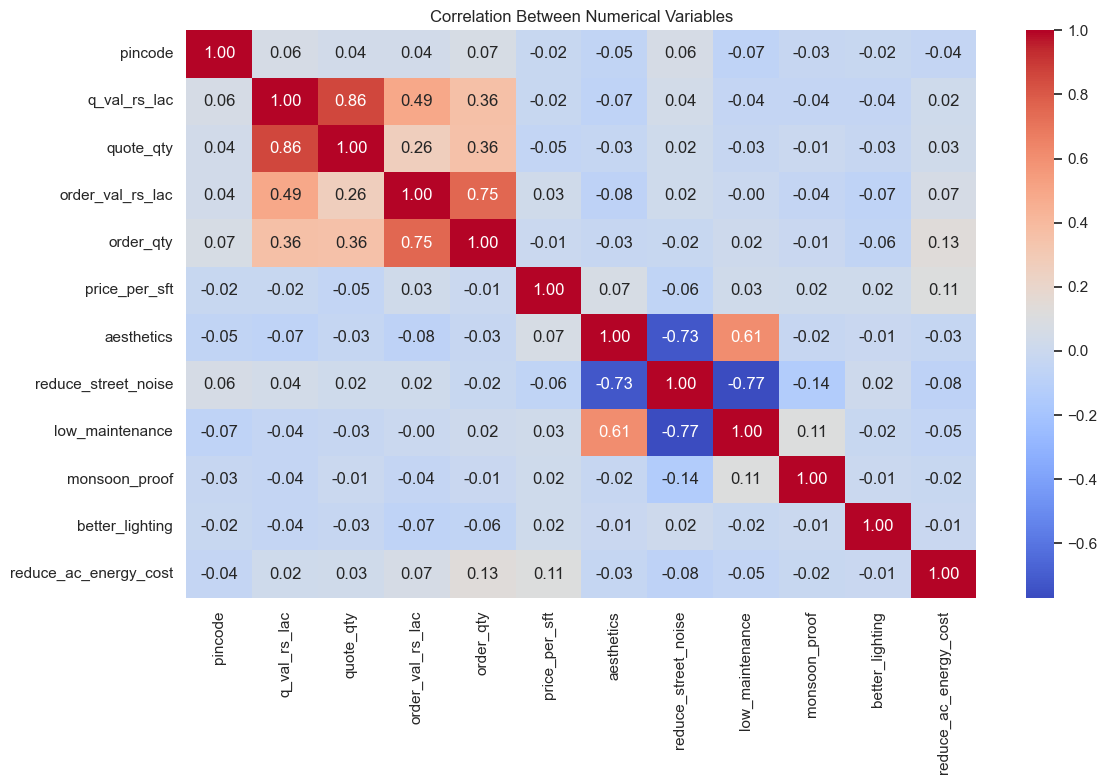

In [24]:
if len(numeric_cols) >= 2:
    correlation_matrix = df[numeric_cols].corr()

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm"
    )

    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.savefig(CHART_DIR / "correlation_heatmap.png", dpi=150)
    plt.show()

    correlation_matrix.to_csv(
        TABLE_DIR / "correlation_matrix.csv"
    )
else:
    correlation_matrix = pd.DataFrame()
    print("At least two numerical columns are required.")

# Outlier Results

In [25]:
outlier_results = []

for col in numeric_cols:
    series = df[col].dropna()

    if len(series) < 4:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = int(((series < lower) | (series > upper)).sum())

    outlier_results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier Percentage": round(count / len(series) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

outlier_report.to_csv(
    TABLE_DIR / "outlier_report.csv",
    index=False
)

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,pincode,599934.00,600198.00,34,14.85
1,q_val_rs_lac,-0.90,3.26,25,10.92
2,quote_qty,-5.50,14.50,29,12.66
3,order_val_rs_lac,1.15,1.15,48,20.96
4,order_qty,6.00,6.00,45,19.65
5,price_per_sft,609.00,1441.00,7,3.06
6,aesthetics,0.00,0.00,9,3.93
7,reduce_street_noise,1.00,1.00,13,5.68
8,low_maintenance,0.00,0.00,18,7.86
9,monsoon_proof,0.00,0.00,3,1.31


In [26]:
monthly_sales = pd.DataFrame()

if date_col and sales_col:
    temp = df[[date_col, sales_col]].copy()
    temp[date_col] = pd.to_datetime(temp[date_col], errors="coerce")
    temp[sales_col] = pd.to_numeric(temp[sales_col], errors="coerce")
    temp = temp.dropna(subset=[date_col, sales_col])

    if not temp.empty:
        temp["Month"] = temp[date_col].dt.to_period("M").astype(str)

        monthly_sales = (
            temp.groupby("Month", as_index=False)[sales_col]
            .sum()
            .sort_values("Month")
        )

        display(monthly_sales)

        fig = px.line(
            monthly_sales,
            x="Month",
            y=sales_col,
            markers=True,
            title="Monthly Sales Trend"
        )

        fig.show()
        fig.write_html(str(CHART_DIR / "monthly_sales.html"))

        monthly_sales.to_csv(
            TABLE_DIR / "monthly_sales.csv",
            index=False
        )
    else:
        print("No valid date and sales records found.")
else:
    print("Monthly sales analysis requires date and sales columns.")

Monthly sales analysis requires date and sales columns.


In [27]:
monthly_profit = pd.DataFrame()

if date_col and profit_col:
    temp = df[[date_col, profit_col]].copy()
    temp[date_col] = pd.to_datetime(temp[date_col], errors="coerce")
    temp[profit_col] = pd.to_numeric(temp[profit_col], errors="coerce")
    temp = temp.dropna(subset=[date_col, profit_col])

    if not temp.empty:
        temp["Month"] = temp[date_col].dt.to_period("M").astype(str)

        monthly_profit = (
            temp.groupby("Month", as_index=False)[profit_col]
            .sum()
            .sort_values("Month")
        )

        fig = px.bar(
            monthly_profit,
            x="Month",
            y=profit_col,
            title="Monthly Profit Trend"
        )

        fig.show()
        fig.write_html(str(CHART_DIR / "monthly_profit.html"))

        monthly_profit.to_csv(
            TABLE_DIR / "monthly_profit.csv",
            index=False
        )
else:
    print("Monthly profit analysis requires date and profit columns.")

Monthly profit analysis requires date and profit columns.


In [28]:
product_sales = pd.DataFrame()

if product_col and sales_col:
    product_sales = (
        df.groupby(product_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .head(10)
        .reset_index()
    )

    display(product_sales)

    fig = px.bar(
        product_sales.sort_values(sales_col),
        x=sales_col,
        y=product_col,
        orientation="h",
        title="Top 10 Products by Sales"
    )

    fig.show()
    fig.write_html(str(CHART_DIR / "top_products.html"))

    product_sales.to_csv(
        TABLE_DIR / "top_products.csv",
        index=False
    )
else:
    print("Product sales analysis is unavailable.")

Product sales analysis is unavailable.


In [29]:
category_sales = pd.DataFrame()

if category_col and sales_col:
    category_sales = (
        df.groupby(category_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    display(category_sales)

    fig = px.bar(
        category_sales,
        x=category_col,
        y=sales_col,
        title="Sales by Category",
        color=sales_col
    )

    fig.update_layout(xaxis_tickangle=-35)
    fig.show()
    fig.write_html(str(CHART_DIR / "category_sales.html"))

    category_sales.to_csv(
        TABLE_DIR / "category_sales.csv",
        index=False
    )
else:
    print("Category analysis is unavailable.")

Category analysis is unavailable.


In [30]:
product_profit = pd.DataFrame()

if product_col and profit_col:
    product_profit = (
        df.groupby(product_col, dropna=False)[profit_col]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    display(product_profit.head(10))

    fig = px.bar(
        product_profit.head(10).sort_values(profit_col),
        x=profit_col,
        y=product_col,
        orientation="h",
        title="Top 10 Products by Profit"
    )

    fig.show()
    fig.write_html(str(CHART_DIR / "product_profitability.html"))

    product_profit.to_csv(
        TABLE_DIR / "product_profitability.csv",
        index=False
    )
else:
    print("Profitability analysis is unavailable.")

Profitability analysis is unavailable.


In [31]:
customer_sales = pd.DataFrame()

if customer_col and sales_col:
    customer_sales = (
        df.groupby(customer_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .head(10)
        .reset_index()
    )

    display(customer_sales)

    fig = px.bar(
        customer_sales.sort_values(sales_col),
        x=sales_col,
        y=customer_col,
        orientation="h",
        title="Top 10 Customers by Sales"
    )

    fig.show()
    fig.write_html(str(CHART_DIR / "customer_sales.html"))

    customer_sales.to_csv(
        TABLE_DIR / "customer_sales.csv",
        index=False
    )
else:
    print("Customer sales analysis is unavailable.")

Customer sales analysis is unavailable.


In [32]:
customer_sales = pd.DataFrame()

if customer_col and sales_col:
    customer_sales = (
        df.groupby(customer_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .head(10)
        .reset_index()
    )

    display(customer_sales)

    fig = px.bar(
        customer_sales.sort_values(sales_col),
        x=sales_col,
        y=customer_col,
        orientation="h",
        title="Top 10 Customers by Sales"
    )

    fig.show()
    fig.write_html(str(CHART_DIR / "customer_sales.html"))

    customer_sales.to_csv(
        TABLE_DIR / "customer_sales.csv",
        index=False
    )
else:
    print("Customer sales analysis is unavailable.")

Customer sales analysis is unavailable.


In [33]:
regional_sales = pd.DataFrame()

if region_col and sales_col:
    regional_sales = (
        df.groupby(region_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    display(regional_sales)

    fig = px.bar(
        regional_sales,
        x=region_col,
        y=sales_col,
        title="Sales by Region"
    )

    fig.update_layout(xaxis_tickangle=-35)
    fig.show()
    fig.write_html(str(CHART_DIR / "regional_sales.html"))

    regional_sales.to_csv(
        TABLE_DIR / "regional_sales.csv",
        index=False
    )
else:
    print("Regional analysis is unavailable.")

Regional analysis is unavailable.


In [34]:
average_order_value = None
order_sales = pd.Series(dtype=float)

if order_col and sales_col:
    order_sales = df.groupby(order_col)[sales_col].sum(min_count=1).dropna()

    if not order_sales.empty:
        average_order_value = float(order_sales.mean())

        print("Unique orders:", len(order_sales))
        print(f"Average order value: {average_order_value:,.2f}")

        order_sales.rename("Order Sales").to_csv(
            TABLE_DIR / "order_sales.csv"
        )

        plt.figure(figsize=(9, 5))
        sns.histplot(order_sales, bins=25, kde=True)
        plt.title("Distribution of Order Values")
        plt.xlabel("Order Value")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "order_value_distribution.png", dpi=150)
        plt.show()
else:
    print("Order analysis requires order ID and sales columns.")

Order analysis requires order ID and sales columns.


In [35]:
insights = []

if total_sales is not None:
    insights.append(f"Total recorded sales: {total_sales:,.2f}.")

if total_profit is not None:
    insights.append(f"Total recorded profit: {total_profit:,.2f}.")

if product_col and not product_sales.empty:
    best_product = product_sales.iloc[0][product_col]
    best_sales = product_sales.iloc[0][sales_col]

    insights.append(
        f"Top-selling product: {best_product} "
        f"(sales: {best_sales:,.2f})."
    )

if category_col and not category_sales.empty:
    best_category = category_sales.iloc[0][category_col]

    insights.append(
        f"Highest-sales category: {best_category}."
    )

if region_col and not regional_sales.empty:
    best_region = regional_sales.iloc[0][region_col]

    insights.append(
        f"Highest-sales region: {best_region}."
    )

if customer_col:
    insights.append(
        f"Distinct customers: {df[customer_col].nunique():,}."
    )

if average_order_value is not None:
    insights.append(
        f"Average order value: {average_order_value:,.2f}."
    )

if not insights:
    insights.append(
        "Review the data dictionary and available numeric fields "
        "to identify suitable retail performance measures."
    )

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

with open(
    OUTPUT_DIR / "business_insights.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("RETAIL ANALYTICS BUSINESS INSIGHTS\n\n")
    f.write("\n".join(f"{i}. {x}" for i, x in enumerate(insights, 1)))

1. Distinct customers: 2.


In [36]:
recommendations = [
    "Review data quality regularly and investigate duplicate or invalid transactions."
]

if product_col and sales_col:
    recommendations.append(
        "Use product sales rankings to support inventory planning, "
        "while checking stock levels and profit margins."
    )

if category_col and sales_col:
    recommendations.append(
        "Compare category sales and category profitability before "
        "increasing promotional spending."
    )

if customer_col and sales_col:
    recommendations.append(
        "Analyze customer purchasing patterns to identify retention "
        "and repeat-purchase opportunities."
    )

if region_col and sales_col:
    recommendations.append(
        "Compare regional performance and investigate potential "
        "differences in demand, availability, and operating costs."
    )

if profit_col:
    recommendations.append(
        "Investigate negative-profit transactions and products "
        "before expanding sales volume."
    )

if date_col and sales_col:
    recommendations.append(
        "Use historical sales trends to support demand planning, "
        "and validate forecasts against later observations."
    )

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

with open(
    OUTPUT_DIR / "business_recommendations.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(
        f"{i}. {x}" for i, x in enumerate(recommendations, 1)
    ))

1. Review data quality regularly and investigate duplicate or invalid transactions.


In [37]:
segment_summary = pd.DataFrame()

if sales_col:
    sales_values = pd.to_numeric(df[sales_col], errors="coerce")

    if sales_values.notna().any():
        q1 = sales_values.quantile(0.25)
        q2 = sales_values.quantile(0.50)
        q3 = sales_values.quantile(0.75)

        def sales_segment(value):
            if pd.isna(value):
                return "Unknown"
            if value <= q1:
                return "Low"
            if value <= q2:
                return "Moderate"
            if value <= q3:
                return "High"
            return "Very High"

        df["sales_segment"] = sales_values.apply(sales_segment)

        segment_summary = (
            df.groupby("sales_segment", dropna=False)
            .agg(
                Transaction_Count=(sales_col, "size"),
                Total_Sales=(sales_col, "sum"),
                Average_Sales=(sales_col, "mean")
            )
            .reset_index()
        )

        display(segment_summary)

        segment_summary.to_csv(
            TABLE_DIR / "sales_segmentation.csv",
            index=False
        )
else:
    print("Sales segmentation is unavailable.")

Sales segmentation is unavailable.


In [38]:
if sales_col and profit_col:
    comparison = df[[sales_col, profit_col]].copy()

    comparison[sales_col] = pd.to_numeric(
        comparison[sales_col], errors="coerce"
    )
    comparison[profit_col] = pd.to_numeric(
        comparison[profit_col], errors="coerce"
    )

    comparison = comparison.dropna()

    if len(comparison) >= 2:
        pearson_corr = comparison[sales_col].corr(
            comparison[profit_col]
        )

        spearman_corr = comparison[sales_col].corr(
            comparison[profit_col], method="spearman"
        )

        print(f"Pearson correlation: {pearson_corr:.3f}")
        print(f"Spearman correlation: {spearman_corr:.3f}")

        fig = px.scatter(
            comparison,
            x=sales_col,
            y=profit_col,
            title="Sales vs. Profit"
        )

        fig.show()
        fig.write_html(str(CHART_DIR / "sales_vs_profit.html"))
    else:
        print("Insufficient records for correlation analysis.")
else:
    print("Sales-profit comparison is unavailable.")

Sales-profit comparison is unavailable.


In [39]:
forecast_results = pd.DataFrame()
forecast_metrics = {}

if date_col and sales_col:
    forecast_df = df[[date_col, sales_col]].copy()

    forecast_df[date_col] = pd.to_datetime(
        forecast_df[date_col], errors="coerce"
    )
    forecast_df[sales_col] = pd.to_numeric(
        forecast_df[sales_col], errors="coerce"
    )

    forecast_df = forecast_df.dropna(
        subset=[date_col, sales_col]
    )

    if not forecast_df.empty:
        forecast_df["Month"] = (
            forecast_df[date_col].dt.to_period("M")
        )

        monthly = (
            forecast_df.groupby("Month")[sales_col]
            .sum()
            .sort_index()
            .to_frame("Sales")
        )

        # Fill missing calendar months with zero only if the source
        # is intended to represent complete monthly sales activity.
        # Otherwise, do not assume an absent month means zero sales.
        if len(monthly) >= 8:
            monthly = monthly.asfreq("M")

            if monthly["Sales"].isna().any():
                print(
                    "Forecast skipped: gaps exist in monthly history. "
                    "Validate the missing periods before modeling."
                )
            else:
                for lag in [1, 2, 3]:
                    monthly[f"lag_{lag}"] = (
                        monthly["Sales"].shift(lag)
                    )

                monthly["rolling_mean_3"] = (
                    monthly["Sales"].shift(1)
                    .rolling(3)
                    .mean()
                )

                model_data = monthly.dropna().copy()

                if len(model_data) >= 6:
                    feature_cols = [
                        "lag_1", "lag_2", "lag_3", "rolling_mean_3"
                    ]

                    split_idx = max(
                        int(len(model_data) * 0.8),
                        len(model_data) - 3
                    )
                    split_idx = min(split_idx, len(model_data) - 1)

                    X = model_data[feature_cols]
                    y = model_data["Sales"]

                    X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
                    y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

                    model = RandomForestRegressor(
                        n_estimators=200,
                        random_state=RANDOM_STATE,
                        min_samples_leaf=2
                    )

                    model.fit(X_train, y_train)
                    predictions = model.predict(X_test)

                    forecast_metrics = {
                        "MAE": float(mean_absolute_error(y_test, predictions)),
                        "RMSE": float(np.sqrt(
                            mean_squared_error(y_test, predictions)
                        )),
                        "R2": (
                            float(r2_score(y_test, predictions))
                            if len(y_test) >= 2 else None
                        )
                    }

                    forecast_results = pd.DataFrame({
                        "Month": y_test.index.astype(str),
                        "Actual Sales": y_test.values,
                        "Predicted Sales": predictions
                    })

                    display(forecast_results)
                    display(pd.DataFrame([
                        {"Metric": k, "Value": v}
                        for k, v in forecast_metrics.items()
                    ]))

                    fig = px.line(
                        forecast_results,
                        x="Month",
                        y=["Actual Sales", "Predicted Sales"],
                        markers=True,
                        title="Monthly Sales: Actual vs Predicted"
                    )

                    fig.show()
                    fig.write_html(
                        str(CHART_DIR / "sales_prediction.html")
                    )

                    forecast_results.to_csv(
                        TABLE_DIR / "sales_predictions.csv",
                        index=False
                    )

                    with open(
                        OUTPUT_DIR / "forecast_metrics.json",
                        "w",
                        encoding="utf-8"
                    ) as f:
                        json.dump(forecast_metrics, f, indent=4)
                else:
                    print("Insufficient history after lag preparation.")
        else:
            print(
                "Forecast skipped: at least eight observed months "
                "are required for this demonstration."
            )
else:
    print("Forecasting requires valid date and numeric sales columns.")

Forecasting requires valid date and numeric sales columns.


In [40]:
cleaned_csv_path = OUTPUT_DIR / "cleaned_retail_data.csv"

df.to_csv(
    cleaned_csv_path,
    index=False,
    encoding="utf-8"
)

print("Cleaned dataset exported successfully.")
print("Location:", cleaned_csv_path.resolve())
print("Rows:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset exported successfully.
Location: C:\Users\amans\retail_analytics_output\cleaned_retail_data.csv
Rows: 229
Columns: 39
